# 08 — Evaluation, Final Recommendations & Conclusions
**Event Recommendation System** · Stages 9 & 10

Explain the metrics, run the **one-time test-set evaluation** with the settings chosen on validation, and draw conclusions.

### Setup (run this first)
- **In Google Colab** this cell downloads the project from GitHub (data + `src/` code) and moves into it.
- **On your own computer** it just moves from `notebooks/` to the project root.

`sys.path.insert(0, "src")` lets us `import recsys` - the small package that holds the reusable code (cleaning, models, metrics). Notebooks *explain* the code; `src/recsys` *stores* it so every notebook uses exactly the same implementation.

In [1]:
import os, sys, subprocess

REPO_URL = "https://github.com/Abdelrahman2115/recommender-system.git"

if "google.colab" in sys.modules:                       # running inside Google Colab
    if not os.path.exists("/content/recommender-system"):
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/recommender-system"], check=True)
    os.chdir("/content/recommender-system")
elif os.path.basename(os.getcwd()) == "notebooks":      # running locally from the notebooks folder
    os.chdir("..")

sys.path.insert(0, "src")                               # make `import recsys` work
print("Project root:", os.getcwd())

Project root: /home/claude/recommender-system


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from recsys.data import load_clean, temporal_split, VAL_END, DATA_END
from recsys.features import EventFeaturizer
from recsys.models import (ContentBasedRecommender, PureSVDRecommender, FunkSVD, HybridRanker, HybridRatingPredictor,
                           RandomRecommender, PopularityRecommender, GlobalMeanPredictor)
from recsys.evaluation import make_ranking_task, evaluate_ranking, evaluate_rating, recommend, bootstrap_ci, RankingTask
from recsys.metrics import precision_at_k, recall_at_k, ndcg_at_k, mae, rmse
from recsys.params import load_params
from recsys.plotting import set_style, bar_labels, MODEL_COLORS, MAIN, TEXT
import os
set_style()
os.makedirs("reports/figures", exist_ok=True)

## 1. The metrics, explained

### Rating metrics — "how many stars off are we?"
| Metric | Formula | Meaning |
|---|---|---|
| **MAE** | mean of \|actual − predicted\| | average mistake in stars. MAE 0.8 = typically 0.8 stars off |
| **RMSE** | √(mean of (actual − predicted)²) | squares the errors first, so **big mistakes count much more**. Always ≥ MAE |

### Ranking metrics — "are the top 10 events the right ones?"
For one user, let *rel* = events they actually went to/attended in the test period.

| Metric | Formula | Meaning |
|---|---|---|
| **Precision@10** | hits in top 10 / 10 | how much of what we showed was useful |
| **Recall@10** | hits in top 10 / \|rel\| | how much of what they wanted we found |
| **NDCG@10** | DCG / ideal DCG, with DCG = Σ 1/log₂(position + 1) over hits | like recall, but a hit at position 1 is worth more than a hit at position 10; 1.0 = perfect order |

Each is computed per user, then averaged over users.

### A worked example

In [3]:
recommended = [11, 22, 33, 44, 55, 66, 77, 88, 99, 100]   # our top-10 for one user, best first
relevant = {22, 77, 500}                                   # what the user actually attended (500 was not recommended)

print("Precision@10 =", precision_at_k(recommended, relevant))        # 2 hits / 10
print("Recall@10    =", round(recall_at_k(recommended, relevant), 4)) # 2 hits / 3 relevant
dcg = 1 / np.log2(2 + 1) + 1 / np.log2(7 + 1)                         # hits at positions 2 and 7
idcg = 1 / np.log2(1 + 1) + 1 / np.log2(2 + 1) + 1 / np.log2(3 + 1)  # best case: 3 hits at positions 1, 2, 3
print("NDCG@10      =", round(ndcg_at_k(recommended, relevant), 4), "| by hand:", round(dcg / idcg, 4))

assert precision_at_k(recommended, relevant) == 0.2
assert np.isclose(ndcg_at_k(recommended, relevant), dcg / idcg)
assert np.isclose(ndcg_at_k([22, 77, 500, 11, 33, 44, 55, 66, 88, 99], relevant), 1.0)   # all hits first -> 1

Precision@10 = 0.2
Recall@10    = 0.6667
NDCG@10      = 0.4525 | by hand: 0.4525


### Why Precision@10 looks "low"
If a user attended only 2 events in the test period, even a **perfect** recommender can get at most 2 hits out of 10 → Precision@10 = 0.2. So precision must be read next to the **best possible** value, which we compute below. Recall and NDCG do not have this ceiling problem.

## 2. Final protocol
1. Merge train + validation → all data before **1 Sep 2025** (the models are re-trained on it, since validation is no longer needed for choices).
2. Use the hyperparameters chosen on validation (notebooks 05–07, stored in `reports/best_params.json`).
3. Recommend events taking place between 1 Sep and 31 Dec 2025; evaluate **once**.

In [4]:
users, events, inter = load_clean()
train, val, test = temporal_split(inter)
history = pd.concat([train, val], ignore_index=True)          # everything known on 1 Sep 2025
P = load_params()

cbf = ContentBasedRecommender(
    EventFeaturizer(category_weight=P["cbf"]["category_weight"], city_weight=P["cbf"]["city_weight"]),
    interest_strength=P["cbf"]["interest_strength"], city_strength=P["cbf"]["city_strength"],
    neighbor_shrinkage=P["cbf"]["neighbor_shrinkage"]).fit(history, users, events)
pure = PureSVDRecommender(n_factors=P["pure_svd"]["n_factors"]).fit(history, users, events)
hybrid = HybridRanker(cbf, pure, P["hybrid"]["cf_weight"], P["hybrid"]["confidence_k"]).fit(history)

task = make_ranking_task(history, test, events, VAL_END, DATA_END)
n_rel = pd.Series({u: len(s) for u, s in task.relevant.items()})
best_possible_p10 = (n_rel.clip(upper=10) / 10).mean()
print(f"test users: {len(task.relevant)} | candidate events: {len(task.candidates)} | "
      f"relevant events per user: {n_rel.mean():.2f} | best possible Precision@10: {best_possible_p10:.3f}")

test users: 1472 | candidate events: 135 | relevant events per user: 3.19 | best possible Precision@10: 0.299


## 3. Ranking results on the test set

In [5]:
ranking_models = {"Random": RandomRecommender(), "Popularity": PopularityRecommender().fit(history),
                  "Content-Based": cbf, "SVD": pure, "Hybrid": hybrid}
per_user = {name: evaluate_ranking(m, task) for name, m in ranking_models.items()}

metrics = ["precision@10", "recall@10", "ndcg@10"]
ranking_table = pd.DataFrame({k: v[metrics].mean() for k, v in per_user.items()}).T
ranking_table["NDCG@10 95% CI"] = [ "[{:.3f}, {:.3f}]".format(*bootstrap_ci(per_user[k]["ndcg@10"])) for k in ranking_table.index]
ranking_table.round(4)

,precision@10,recall@10,ndcg@10,NDCG@10 95% CI
Random,0.0243,0.0753,0.0477,"[0.042, 0.054]"
Popularity,0.0395,0.1269,0.0900,"[0.081, 0.099]"
Content-Based,0.1493,0.5301,0.3533,"[0.339, 0.367]"
SVD,0.0515,0.1697,0.1557,"[0.143, 0.169]"
Hybrid,0.1529,0.5464,0.3656,"[0.352, 0.380]"


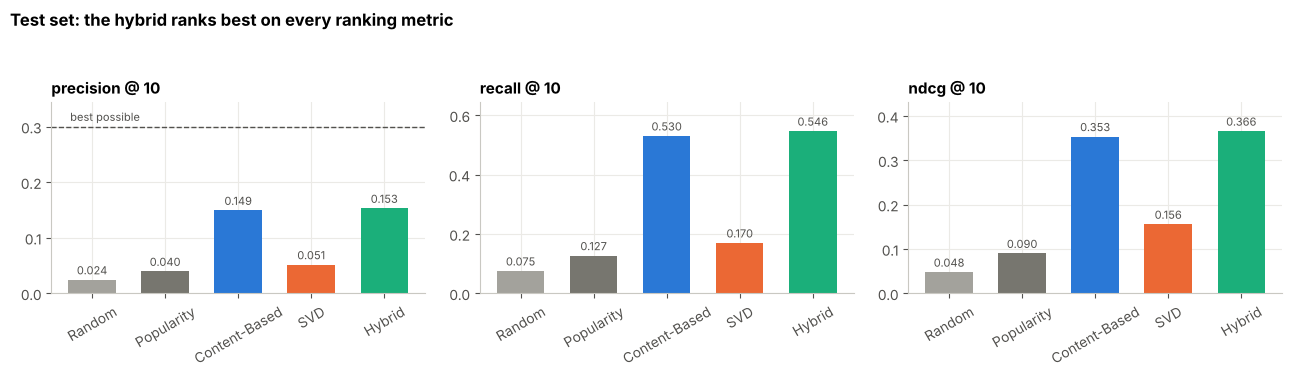

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=False)
for ax, m in zip(axes, metrics):
    vals = ranking_table[m]
    ax.bar(vals.index, vals.values, color=[MODEL_COLORS[n] for n in vals.index], width=0.65)
    bar_labels(ax, fmt="{:.3f}")
    ax.set_title(m.replace("@", " @ "), fontsize=11)
    ax.tick_params(axis="x", rotation=30)
    ax.set_ylim(0, vals.max() * 1.18)
axes[0].set_ylim(0, best_possible_p10 * 1.15)              # make room for the ceiling line
axes[0].axhline(best_possible_p10, color=TEXT, linestyle="--", linewidth=1)
axes[0].text(-0.3, best_possible_p10 * 1.02, "best possible", fontsize=8, color=TEXT, va="bottom")
fig.suptitle("Test set: the hybrid ranks best on every ranking metric", x=0.01, ha="left", fontweight="bold")
plt.tight_layout(rect=[0, 0, 1, 0.93])
fig.savefig("reports/figures/ranking_results.png", dpi=150, bbox_inches="tight")
plt.show()

In [7]:
# Is the hybrid's improvement over content-based real? Paired bootstrap over test users.
diff = per_user["Hybrid"].set_index("user_id")["ndcg@10"] - per_user["Content-Based"].set_index("user_id")["ndcg@10"]
lo, hi = bootstrap_ci(diff)
print(f"Hybrid - Content-Based NDCG@10: {diff.mean():+.4f}  (95% CI [{lo:+.4f}, {hi:+.4f}])")

Hybrid - Content-Based NDCG@10: +0.0123  (95% CI [+0.0057, +0.0192])


## 4. Where does each model work? Events with and without history
Same test, but split by the candidate event's history on 1 Sep: events with ≥5 earlier interactions vs the rest.

events with history (≥5): 25 candidate events, 587 users
new events (<5): 110 candidate events, 1358 users


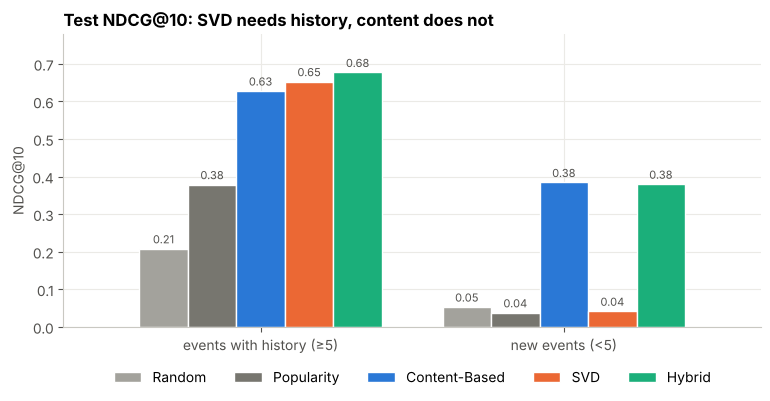

,events with history (≥5),new events (<5)
Random,0.208,0.053
Popularity,0.379,0.038
Content-Based,0.628,0.384
SVD,0.653,0.042
Hybrid,0.677,0.380


In [8]:
n_event = history.groupby("event_id").size()
def sub_task(keep):
    cands = np.array([e for e in task.candidates if keep(n_event.get(e, 0))])
    s = set(cands)
    return RankingTask(cands, {u: r & s for u, r in task.relevant.items() if r & s}, task.seen)

segments = {"events with history (≥5)": sub_task(lambda n: n >= 5), "new events (<5)": sub_task(lambda n: n < 5)}
seg = pd.DataFrame({name: {m: evaluate_ranking(model, t)["ndcg@10"].mean() for m, model in ranking_models.items()}
                    for name, t in segments.items()})
for name, t in segments.items():
    print(f"{name}: {len(t.candidates)} candidate events, {len(t.relevant)} users")

ax = seg.T.plot.bar(color=[MODEL_COLORS[m] for m in seg.index], width=0.8, figsize=(9, 3.8), rot=0, edgecolor="white", linewidth=1)
bar_labels(ax, fmt="{:.2f}")
ax.set_ylim(0, seg.values.max() * 1.15); ax.set_ylabel("NDCG@10")
ax.legend(ncols=5, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("Test NDCG@10: SVD needs history, content does not")
plt.savefig("reports/figures/history_vs_new.png", dpi=150, bbox_inches="tight")
plt.show()
seg.round(3)

**Reading the chart:** on events with history, SVD is the strongest single model and the hybrid is better still. On new events SVD is close to random, and the hybrid scores about the same as content-based filtering (marginally lower: its small fixed SVD weight slightly favours events with some activity, which is not useful when every candidate is new). Overall, most candidates are new, which is why content-based filtering carries most of the weight.

## 5. Coverage: does everyone get the same list?
**Catalog coverage** = share of candidate events that appear in at least one user's top 10. A popularity recommender shows everyone the same 10 events; a personalised one spreads attention across the catalog, which also helps smaller organisers.

In [9]:
coverage = {}
for name, m in ranking_models.items():
    shown = set()
    for u in task.relevant:
        shown.update(recommend(m, u, task.candidates, task.seen.get(u, set())))
    coverage[name] = len(shown) / len(task.candidates)
pd.Series(coverage, name="catalog coverage").map("{:.0%}".format).to_frame()

,catalog coverage
Random,100%
Popularity,17%
Content-Based,100%
SVD,24%
Hybrid,100%


**Reading the table:** popularity recommends the same few events to everyone, and SVD can only push events it has seen. Content-based and hybrid recommendations reach every candidate event.

## 6. Rating prediction on the test set

In [10]:
rated_hist, rated_test = history.dropna(subset=["rating"]), test.dropna(subset=["rating"])
svd = FunkSVD(n_factors=P["svd"]["n_factors"], reg=P["svd"]["reg"], n_epochs=P["svd"]["n_epochs"]).fit(rated_hist)
rating_models = {"Global mean": GlobalMeanPredictor().fit(rated_hist), "Content-Based": cbf, "SVD": svd,
                 "Hybrid": HybridRatingPredictor(cbf, svd, svd_weight=P["hybrid_rating"]["svd_weight"])}
rating_table = pd.DataFrame({k: evaluate_rating(m, rated_test) for k, m in rating_models.items()}).T
rating_table["RMSE vs global mean"] = (rating_table["RMSE"] / rating_table.loc["Global mean", "RMSE"] - 1).map("{:+.1%}".format)
print("test ratings:", len(rated_test))
rating_table.round(4)

test ratings: 3852


,MAE,RMSE,RMSE vs global mean
Global mean,0.8340,0.9859,+0.0%
Content-Based,0.7833,0.9553,-3.1%
SVD,0.7815,0.9492,-3.7%
Hybrid,0.7815,0.9492,-3.7%


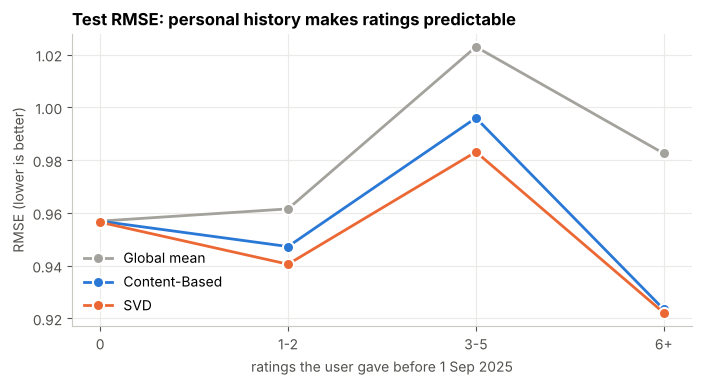

,Global mean,Content-Based,SVD,n
0,0.957,0.957,0.956,445
1-2,0.962,0.947,0.941,1057
3-5,1.023,0.996,0.983,1119
6+,0.983,0.923,0.922,1231


In [11]:
n_prev = rated_test["user_id"].map(rated_hist.groupby("user_id").size()).fillna(0)
groups = pd.cut(n_prev, [-1, 0, 2, 5, 1000], labels=["0", "1-2", "3-5", "6+"])
rows = {g: {name: rmse(rated_test.loc[groups == g, "rating"],
                       m.predict(rated_test.loc[groups == g, "user_id"].to_numpy(), rated_test.loc[groups == g, "event_id"].to_numpy()))
            for name, m in rating_models.items() if name != "Hybrid"} for g in groups.cat.categories}
by_hist = pd.DataFrame(rows).T

fig, ax = plt.subplots(figsize=(8, 3.8))
for name in by_hist.columns:
    ax.plot(by_hist.index.astype(str), by_hist[name], marker="o", markersize=8, linewidth=2, color=MODEL_COLORS[name],
            label=name, markeredgecolor="white", markeredgewidth=1.5)
ax.set_xlabel("ratings the user gave before 1 Sep 2025"); ax.set_ylabel("RMSE (lower is better)")
ax.legend(loc="lower left"); ax.set_title("Test RMSE: personal history makes ratings predictable")
plt.savefig("reports/figures/rating_by_history.png", dpi=150, bbox_inches="tight")
plt.show()
by_hist.assign(n=groups.value_counts().reindex(by_hist.index).values).round(3)

**Reading the results:** SVD has the lowest test error, 3.7% below the global mean (content-based: 3.1%). The breakdown shows why the overall gain is modest: for users with no previous ratings nothing beats the global mean, and the gap widens steadily with each user's history. The rating hybrid's tuned weight is 1.0, so it is identical to SVD.

## 7. Final recommendations
`recommend_for()` is the function a web app would call: given a user, return the top 10 upcoming events with the reasons behind each score.

In [12]:
ev = events.set_index("event_id")
user_info = users.set_index("user_id")

def recommend_for(user_id, k=10):
    """Top-k events happening after 1 Sep 2025 for one user, with score breakdown."""
    top = recommend(hybrid, user_id, task.candidates, task.seen.get(user_id, set()), k)
    out = ev.loc[top, ["title", "category", "city", "price", "start_datetime"]].copy()
    out["content score"] = cbf.score(user_id, top).round(3)
    out["svd score"] = pure.score(user_id, top).round(3)
    out["event history"] = [int(n_event.get(e, 0)) for e in top]
    out["attended? (test)"] = ["✔" if e in task.relevant.get(user_id, set()) else "" for e in top]
    return out

active = history["user_id"].value_counts().index[100]
print("Active user", active, "| interests:", user_info.loc[active, "interests"], "| city:", user_info.loc[active, "city"],
      "| past interactions:", (history["user_id"] == active).sum())
recommend_for(active)

Active user 400 | interests: Education & Workshops|Sports & Fitness | city: Hurghada | past interactions: 46


,title,category,city,price,start_datetime,content score,svd score,event history,attended? (test)
event_id,,,,,,,,,
774,Football Session,Sports & Fitness,Cairo,190.0,2025-09-08 18:00:00,0.560,0.201,50,
149,Running Session,Sports & Fitness,Cairo,0.0,2025-10-07 18:00:00,0.588,0.000,0,
91,Tournament Gathering,Sports & Fitness,Cairo,0.0,2025-11-04 10:00:00,0.572,0.000,0,✔
344,Stretching Gathering,Sports & Fitness,Alexandria,0.0,2025-09-02 12:00:00,0.479,0.472,125,✔
219,Football Gathering,Sports & Fitness,Cairo,50.0,2025-11-26 20:00:00,0.559,0.000,0,
198,Marathon Gathering,Sports & Fitness,Giza,260.0,2025-10-19 10:00:00,0.550,0.000,0,
608,Stretching Gathering,Sports & Fitness,Cairo,0.0,2025-11-23 18:00:00,0.544,0.000,0,
689,Mindfulness Workshop,Sports & Fitness,Cairo,0.0,2025-11-18 19:00:00,0.537,0.000,0,
713,5K Meetup,Sports & Fitness,Cairo,200.0,2025-11-12 10:00:00,0.535,0.000,0,


In [13]:
newcomer = next(u for u in task.relevant if u not in set(history["user_id"]))
print("New user", newcomer, "| interests:", user_info.loc[newcomer, "interests"], "| city:", user_info.loc[newcomer, "city"],
      "| past interactions: 0")
recommend_for(newcomer)

New user 109 | interests: Sports & Fitness|Business & Career | city: Alexandria | past interactions: 0


,title,category,city,price,start_datetime,content score,svd score,event history,attended? (test)
event_id,,,,,,,,,
129,Career Night,Business & Career,Alexandria,110.0,2025-09-25 16:00:00,0.564,0.0,0,
771,Wellness Workshop,Sports & Fitness,Alexandria,0.0,2025-09-21 16:00:00,0.559,0.0,20,✔
344,Stretching Gathering,Sports & Fitness,Alexandria,0.0,2025-09-02 12:00:00,0.559,0.0,125,✔
730,Yoga Workshop,Sports & Fitness,Alexandria,180.0,2025-09-30 12:00:00,0.555,0.0,0,
148,League Gathering,Sports & Fitness,Alexandria,90.0,2025-12-03 10:00:00,0.541,0.0,0,
754,Interview Skills Workshop,Business & Career,Cairo,220.0,2025-11-27 16:00:00,0.384,0.0,0,
636,Intro To Networking,Business & Career,Cairo,110.0,2025-12-19 10:00:00,0.383,0.0,0,
640,Interview Skills Masterclass,Business & Career,Cairo,0.0,2025-10-16 12:00:00,0.383,0.0,0,
592,Networking Night,Business & Career,Cairo,0.0,2025-09-10 10:00:00,0.382,0.0,91,


In [14]:
# save the results tables for the README
ranking_table.round(4).to_csv("reports/ranking_results.csv")
rating_table.round(4).to_csv("reports/rating_results.csv")
print(open("reports/ranking_results.csv").read())
print(open("reports/rating_results.csv").read())

,precision@10,recall@10,ndcg@10,NDCG@10 95% CI
Random,0.0243,0.0753,0.0477,"[0.042, 0.054]"
Popularity,0.0395,0.1269,0.09,"[0.081, 0.099]"
Content-Based,0.1493,0.5301,0.3533,"[0.339, 0.367]"
SVD,0.0515,0.1697,0.1557,"[0.143, 0.169]"
Hybrid,0.1529,0.5464,0.3656,"[0.352, 0.380]"

,MAE,RMSE,RMSE vs global mean
Global mean,0.834,0.9859,+0.0%
Content-Based,0.7833,0.9553,-3.1%
SVD,0.7815,0.9492,-3.7%
Hybrid,0.7815,0.9492,-3.7%



## 8. Conclusions

**Ranking (the main task).** The hybrid is the best model on Precision@10, Recall@10 and NDCG@10, and its gain over content-based filtering is supported by a bootstrap confidence interval. Content-based filtering does most of the work, because most upcoming events are new; SVD contributes where events already have history; popularity is a weak baseline once personalisation is available.

**Rating prediction.** Ratings are hard to predict on a young event platform: most users have few ratings and most rated events are new. SVD gives the lowest error, mainly by learning each user's rating habit, and its advantage grows with the user's history. Blending in content-based predictions does not help for ratings, so the tuned rating hybrid is simply SVD.

**Method.** A global time split, a separate validation period for every choice, and a single final test run mean the numbers above are what the system would score on data it has never seen.

## 9. Limitations
- **Synthetic data.** Results show that the pipeline works on data with realistic structure; they are not evidence about real users. The next step would be the same notebooks on real platform logs.
- **Small catalogue** (800 events, 7 cities). Real platforms have far more events; scoring every candidate would need approximate nearest-neighbour search.
- **Offline evaluation only.** "Attended" in the logs depends on what the old system showed users. A live A/B test is the real measure.
- **No group recommendation.** The original project idea included groups of friends; recommending to a group needs an aggregation strategy (e.g. average or least-misery).

## 10. Future work
- Implicit-feedback models designed for ranking (ALS, BPR, LightFM) and learning-to-rank on top of both models' scores.
- Using event dates and distance explicitly (weekend preference, travel distance).
- Explanations shown to users ("because you attended *Python Meetup*").
- A small web demo (e.g. Streamlit) on top of `recommend_for()`.

### Interview questions for this stage
- *Your Precision@10 is 0.15 — isn't that bad?* — Users attended about 3 test events each, so the best possible Precision@10 is about 0.3. Recall@10 shows that more than half of what users attended is in our top 10 (out of ~135 events), and NDCG@10 shows the hits tend to be near the top.
- *How do you know the hybrid is really better?* — A paired bootstrap over test users gives a confidence interval for the improvement over content-based filtering.
- *What would you do with real data?* — Re-run the same notebooks; only notebook 00 changes. Then validate online with an A/B test, because offline metrics only approximate real behaviour.